# Bloc 2 — Ordonner et regrouper (clustering)
**Fichiers** : `officer_filings`, `public_appointments`, `licensed_facilities`, `licensed_professionals`, `institutional_memos`, `public_and_investigative_documents`.

Pour chaque fichier : a) choix des variables et encodage, b) PCA, t-SNE et choix de la méthode de clustering, c) interprétation des clusters.
Quand le clustering n'est pas pertinent (trop peu de lignes ou de variables), on le justifie.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import linkage, dendrogram

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
REF_DATE = pd.Timestamp("2025-12-31")   # date de référence pour les mandats encore en cours

In [2]:
# on charge les données
officers = pd.read_csv("officer_filings_cleaned.csv", parse_dates=["appointment_date", "cessation_date", "filing_date"])
appointments = pd.read_csv("public_appointments_cleaned.csv", parse_dates=["appointment_start", "appointment_end"])
facilities = pd.read_csv("licensed_facilities_cleaned.csv")
professionals = pd.read_csv("licensed_professionals_cleaned.csv", parse_dates=["license_issue_date"])
memos = pd.read_csv("institutional_memos_cleaned.csv", parse_dates=["document_date"])
documents = pd.read_csv("public_and_investigative_documents_cleaned.csv", parse_dates=["document_date"])
entities = pd.read_csv("registered_entities_cleaned.csv")   # seulement pour avoir le nom des entreprises

## 0. Fonctions communes
Les mêmes étapes reviennent pour chaque fichier : on les écrit une fois.

In [3]:
def projections(X, couleur=None, titre=""):
    # PCA et t-SNE en 2D, côte à côte ; renvoie la variance expliquée par les 2 axes de la PCA
    pca = PCA(n_components=2).fit(X)
    P = pca.transform(X)
    T = TSNE(n_components=2, perplexity=min(30, len(X) // 4), random_state=42, init="pca").fit_transform(X)
    fig, ax = plt.subplots(1, 2, figsize=(13, 5))
    for a, coords, nom in zip(ax, [P, T], ["PCA", "t-SNE"]):
        sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=couleur, ax=a, s=50)
        a.set_title(f"{nom} — {titre}")
    if couleur is not None:
        ax[1].get_legend().remove()
    plt.tight_layout(); plt.show()
    print(f"Variance expliquée par les 2 composantes PCA : {pca.explained_variance_ratio_.sum():.0%}")


def choix_k_kmeans(X, k_range=range(2, 9)):
    # méthode du coude (inertie) et silhouette pour K-Means
    inerties, silhouettes = [], []
    for k in k_range:
        km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
        inerties.append(km.inertia_)
        silhouettes.append(silhouette_score(X, km.labels_))
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(list(k_range), inerties, marker="o"); ax[0].set_title("Méthode du coude (K-Means)"); ax[0].set_xlabel("k")
    ax[1].plot(list(k_range), silhouettes, marker="o", color="green"); ax[1].set_title("Silhouette (K-Means)"); ax[1].set_xlabel("k")
    plt.tight_layout(); plt.show()
    return pd.DataFrame({"k": list(k_range), "silhouette": np.round(silhouettes, 3)}).set_index("k").T


def choix_k_cah_hamming(Xbin, k_range=range(2, 8)):
    # silhouette du clustering agglomératif (distance de Hamming, liaison average) pour plusieurs k
    res = {}
    for k in k_range:
        lab = AgglomerativeClustering(n_clusters=k, metric="hamming", linkage="average").fit_predict(Xbin)
        res[k] = round(silhouette_score(Xbin, lab, metric="hamming"), 3)
    return pd.DataFrame({"silhouette (Hamming)": res}).T


def courbe_eps(X, k=5, metric="euclidean"):
    # distance au k-ième voisin, triée : on choisit eps au niveau du "décrochage" de la courbe
    d = np.sort(NearestNeighbors(n_neighbors=k, metric=metric).fit(X).kneighbors(X)[0][:, -1])
    plt.figure(figsize=(5, 3)); plt.plot(d)
    plt.title(f"Distance au {k}e voisin (choix de eps)"); plt.xlabel("points triés"); plt.ylabel("distance")
    plt.tight_layout(); plt.show()


def profil_clusters(df, labels, cols):
    # pour chaque cluster : taille et modalité la plus fréquente de chaque variable (avec sa part)
    lignes = {}
    for c in sorted(set(labels)):
        sub = df[labels == c]
        ligne = {"n": len(sub)}
        for col in cols:
            top = sub[col].mode()[0]
            ligne[col] = f"{top} ({(sub[col] == top).mean():.0%})"
        lignes[c] = ligne
    return pd.DataFrame(lignes).T

---
## 1. officer_filings
*(exploration dans `bloc1_exploration.ipynb`)*

### a) choix des variables et encodage
On garde l'année de nomination, l'âge à la nomination, la durée du mandat, le statut (actif = 1) et la nationalité.
On exclut les identifiants, `filing_delay_days` (tiré au hasard), l'année de naissance (redondante avec l'année de nomination, corrélation 0,98), `role_title` et `service_address` (quasi uniques).
La durée des mandats en cours est calculée jusqu'au 31/12/2025, car le clustering n'accepte pas de valeurs manquantes.
Les variables sont mixtes (numériques + nationalité en one-hot) : on **standardise** pour que les durées en jours n'écrasent pas le reste, et on utilise la distance euclidienne.

In [4]:
of = officers.copy()
of["appointment_year"] = of["appointment_date"].dt.year
b = of["birth_year_or_age_band"]
annee_exacte = pd.to_numeric(b.where(b.str.fullmatch(r"\d{4}")), errors="coerce")
milieu_tranche = b.str.extract(r"(\d{4})\D+(\d{4})").astype(float).mean(axis=1)
of["age_at_appointment"] = of["appointment_year"] - annee_exacte.fillna(milieu_tranche)
of["tenure_to_ref_days"] = (of["cessation_date"].fillna(REF_DATE) - of["appointment_date"]).dt.days
of["is_active"] = (of["filing_status"] == "active").astype(int)

X_of_df = pd.concat([of[["appointment_year", "age_at_appointment", "tenure_to_ref_days", "is_active"]],
                     pd.get_dummies(of["nationality_or_region"], prefix="nat", dtype=int)], axis=1)
X_of = StandardScaler().fit_transform(X_of_df)
print("Dimensions :", X_of.shape)

Dimensions : (135, 9)


### b) PCA, t-SNE, et choix de la méthode de clustering

Variance expliquée par les 2 composantes PCA : 41%


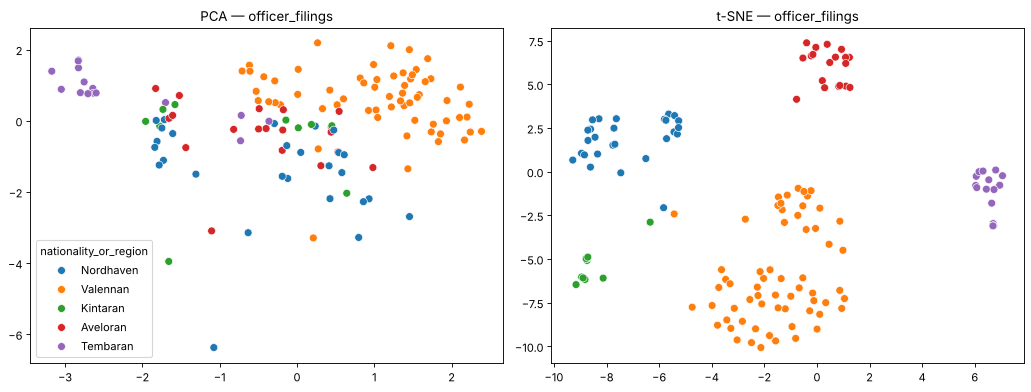

In [5]:
projections(X_of, couleur=of["nationality_or_region"], titre="officer_filings")

Les deux axes de la PCA ne gardent que 41 % de la variance (les 5 colonnes de nationalité dispersent l'information). La t-SNE forme des îlots par nationalité, effet attendu du one-hot.
Les variables étant en partie numériques, on part sur **K-Means**, comparé au **clustering agglomératif (Ward)**, puis **DBSCAN** pour repérer les points isolés.

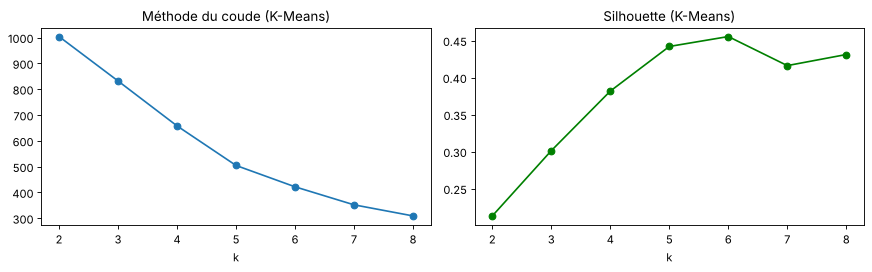

k,2,3,4,5,6,7,8
silhouette,0.213,0.301,0.382,0.442,0.455,0.416,0.431


In [6]:
choix_k_kmeans(X_of)

Le coude n'est pas net. La silhouette est maximale à k = 6 (0,455) mais k = 5 est quasi équivalent (0,442) : on retient **k = 5**, le nombre de nationalités, plus lisible.

In [7]:
k_of = 5
of["Cluster_KMeans"] = KMeans(n_clusters=k_of, n_init=10, random_state=42).fit_predict(X_of)
of["Cluster_Agglom"] = AgglomerativeClustering(n_clusters=k_of, linkage="ward").fit_predict(X_of)
print(f"ARI K-Means vs CAH : {adjusted_rand_score(of['Cluster_KMeans'], of['Cluster_Agglom']):.2f}")
print(pd.crosstab(of["Cluster_KMeans"], of["Cluster_Agglom"], rownames=["K-Means"], colnames=["CAH"]))

of.groupby("Cluster_KMeans").agg(
    n=("filing_id", "size"),
    nationalite=("nationality_or_region", lambda s: s.mode()[0]),
    annee_mediane=("appointment_year", "median"),
    duree_mediane_ans=("tenure_to_ref_days", lambda s: round(s.median() / 365.25, 1)),
    part_actifs=("is_active", lambda s: round(s.mean(), 2)),
)

ARI K-Means vs CAH : 0.94
CAH       0   1   2   3   4
K-Means                    
0         0   0  17   0   0
1         1  61   0   0   0
2         1   1   0   0  25
3        10   0   0   0   0
4         1   0   0  18   0


,n,nationalite,annee_mediane,duree_mediane_ans,part_actifs
Cluster_KMeans,,,,,
0,17,Tembaran,1997.0,7.0,0.24
1,62,Valennan,2001.0,18.5,0.68
2,27,Nordhaven,1999.0,15.0,0.56
3,10,Kintaran,2001.5,13.5,0.40
4,19,Aveloran,2004.0,19.0,0.63


Points de bruit (DBSCAN) : 22


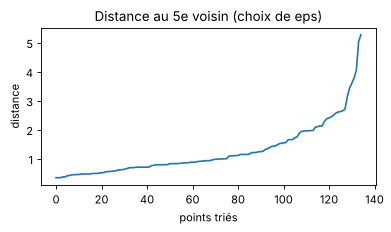

,full_name,nationality_or_region,appointment_date,cessation_date
0,Edward Vann,Nordhaven,1840-01-01,1888-12-31
4,J. Varlan,Kintaran,1885-01-01,1918-12-31
1,Emil Warden,Valennan,1895-01-01,1943-12-31
5,Jonah Bell,Aveloran,1924-01-01,1963-12-31
2,Adrian Vosmere,Nordhaven,1952-01-01,1991-12-31
17,Rayan Belen,Kintaran,1981-01-01,NaT
24,Oskar Nivren,Nordhaven,1987-01-01,1998-12-31
58,Kira Norel,Tembaran,1990-01-01,NaT
115,Bela Waren,Kintaran,1990-01-01,1993-12-31
27,Rayan Belen,Kintaran,1993-01-01,2002-12-31


In [8]:
courbe_eps(X_of, k=5)
of["Cluster_DBSCAN"] = DBSCAN(eps=1.5, min_samples=5).fit_predict(X_of)
print("Points de bruit (DBSCAN) :", (of["Cluster_DBSCAN"] == -1).sum())
of.loc[of["Cluster_DBSCAN"] == -1, ["full_name", "nationality_or_region", "appointment_date", "cessation_date"]].sort_values("appointment_date").head(10)

### c) Interprétation des clusters de officer_filings
- Les **5 clusters correspondent exactement aux 5 nationalités** (62 Valennans, 27 Nordhaveniens, 19 Avelorans, 17 Tembarans, 10 Kintarans). K-Means et la CAH sont presque identiques (4 déclarations sur 135 changent de groupe) : les groupes sont stables, mais ils ne révèlent pas de structure cachée.
- Seul le cluster **tembaran** se distingue : 24 % de mandats en cours et des mandats courts (7 ans en médiane), des postes « de passage ».
- **DBSCAN** classe 22 déclarations en bruit : les **5 nominations antérieures à 1960** (Vann 1840, Varlan 1885, Warden 1895, Bell 1924, Vosmere 1952), des **carrières de dirigeants très longues** (Belen, Nivren, Solva), et des Kintarans / Tembarans isolés par la petite taille de leur nationalité.

Remarque : l'information utile est dans les déclarations isolées, étudiées au bloc 3.

---
## 2. public_appointments

### a) choix des variables et encodage
On exclut les identifiants (`appointment_record_id`, `source_notice_reference`), le nom et le titre exact du poste (presque une modalité par ligne).
On exclut aussi `appointment_basis` (**constante** : « appointed » partout) et `official_region` (**identique** à `appointing_jurisdiction` sur les 62 lignes).
On construit :
- l'année de début, la durée du mandat (jusqu'au 31/12/2025 s'il est en cours), le statut (en cours = 1) et l'âge au début ;
- un **niveau hiérarchique** à partir du titre : 1 = agent / chargé de programme, 2 = cadre (directeur, ministre adjoint…), 3 = sommet de l'État (chef de gouvernement, gouverneur, président du conseil…).

La juridiction et l'institution sont encodées en one-hot, puis tout est standardisé.

In [9]:
ap = appointments.copy()
print("appointment_basis :", ap["appointment_basis"].unique().tolist())
print("official_region identique à appointing_jurisdiction :", (ap["official_region"] == ap["appointing_jurisdiction"]).all())

ap["start_year"] = ap["appointment_start"].dt.year
ap["is_open"] = ap["appointment_end"].isna().astype(int)
ap["duration_years"] = (ap["appointment_end"].fillna(REF_DATE) - ap["appointment_start"]).dt.days / 365.25
ap["age_at_start"] = ap["start_year"] - ap["recorded_birth_year"]
ap["age_at_start"] = ap["age_at_start"].fillna(ap["age_at_start"].median())   # 5 années de naissance manquantes


def niveau(titre):
    t = titre.lower()
    if "deputy" in t:
        return 2
    if any(m in t for m in ["head of government", "senior minister", "governor", "council president", "political intermediary"]):
        return 3
    if any(m in t for m in ["minister", "vice-president", "secretary", "director", "commissioner", "coordinator"]):
        return 2
    return 1


ap["rank"] = ap["office_title"].apply(niveau)

X_ap_df = pd.concat([ap[["start_year", "duration_years", "is_open", "age_at_start", "rank"]],
                     pd.get_dummies(ap["appointing_jurisdiction"], prefix="jur", dtype=int),
                     pd.get_dummies(ap["institution_name"], prefix="inst", dtype=int)], axis=1)
X_ap = StandardScaler().fit_transform(X_ap_df)
print("Dimensions :", X_ap.shape)

appointment_basis : ['appointed']
official_region identique à appointing_jurisdiction : True
Dimensions : (62, 17)


5 années de naissance manquantes : on impute l'âge par la médiane, **uniquement pour le clustering**.

### b) PCA, t-SNE, et choix de la méthode de clustering

Variance expliquée par les 2 composantes PCA : 33%


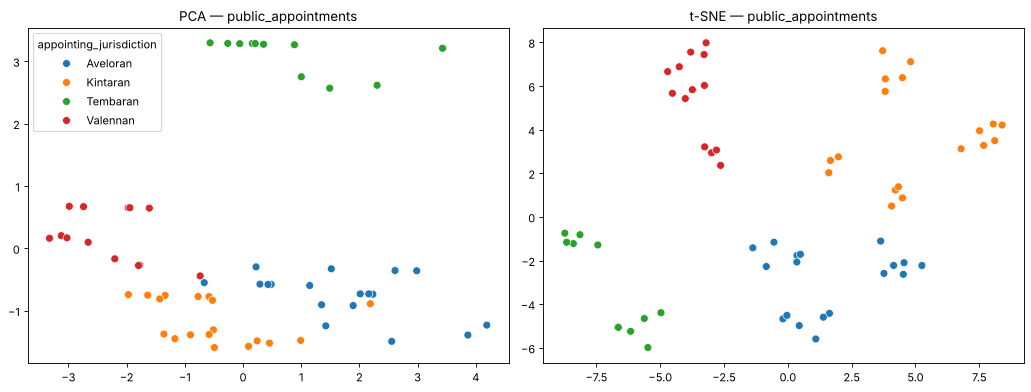

In [10]:
projections(X_ap, couleur=ap["appointing_jurisdiction"], titre="public_appointments")

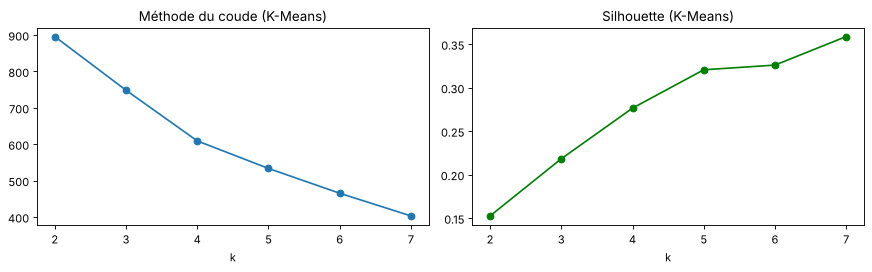

k,2,3,4,5,6,7
silhouette,0.153,0.218,0.277,0.321,0.326,0.359


In [11]:
choix_k_kmeans(X_ap, range(2, 8))

In [12]:
k_ap = 4
ap["Cluster_KMeans"] = KMeans(n_clusters=k_ap, n_init=10, random_state=42).fit_predict(X_ap)
ap["Cluster_Agglom"] = AgglomerativeClustering(n_clusters=k_ap, linkage="ward").fit_predict(X_ap)
print(f"ARI K-Means vs CAH : {adjusted_rand_score(ap['Cluster_KMeans'], ap['Cluster_Agglom']):.2f}")
print(pd.crosstab(ap["Cluster_KMeans"], ap["Cluster_Agglom"], rownames=["K-Means"], colnames=["CAH"]))

ap.groupby("Cluster_KMeans").agg(
    n=("appointment_record_id", "size"),
    juridiction=("appointing_jurisdiction", lambda s: s.mode()[0]),
    debut_median=("start_year", "median"),
    duree_mediane=("duration_years", lambda s: round(s.median(), 1)),
    part_en_cours=("is_open", lambda s: round(s.mean(), 2)),
    niveau_moyen=("rank", lambda s: round(s.mean(), 2)),
)

ARI K-Means vs CAH : 0.51
CAH       0   1  2   3
K-Means               
0         8   0  0  12
1        18   0  0   0
2         0  11  0   0
3         4   0  9   0


,n,juridiction,debut_median,duree_mediane,part_en_cours,niveau_moyen
Cluster_KMeans,,,,,,
0,20,Kintaran,2000.0,10.3,0.45,1.40
1,18,Aveloran,1992.0,25.5,0.67,1.89
2,11,Tembaran,2003.0,19.0,0.73,1.73
3,13,Valennan,2002.0,10.0,0.38,1.08


{-1: 13, 0: 5, 1: 5, 2: 9, 3: 4, 4: 4, 5: 4, 6: 4, 7: 4, 8: 4, 9: 6}


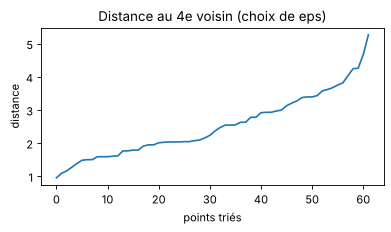

In [13]:
courbe_eps(X_ap, k=4)
ap["Cluster_DBSCAN"] = DBSCAN(eps=3.0, min_samples=4).fit_predict(X_ap)
print(ap["Cluster_DBSCAN"].value_counts().sort_index().to_dict())

### c) Interprétation des clusters de public_appointments
- La silhouette reste faible quel que soit k (0,28 à k = 4) et augmente avec k : il n'y a **pas de structure naturelle forte**. On retient k = 4, le nombre de juridictions.
- Les **4 clusters K-Means correspondent exactement aux 4 juridictions** (20 Kintarans, 18 Avelorans, 11 Tembarans, 13 Valennans). La CAH (Ward) n'est qu'en partie d'accord (ARI = 0,51) : elle mélange une partie des Kintarans et des Valennans, qui servent tous deux en partie dans des institutions avelorannes.
- Le cluster **aveloran** se distingue : nominations plus anciennes (1992 en médiane), mandats longs (25,5 ans) et niveau hiérarchique plus élevé. Le cluster valennan (Orison Medical Audit Board) regroupe des postes récents, courts et de bas niveau.
- **DBSCAN n'est pas pertinent** ici : avec 62 lignes et 17 dimensions, la densité est trop faible et il produit 10 micro-groupes de 4 à 9 points. On retient seulement ses 13 points de bruit : ce sont presque tous les **postes au sommet de l'État** occupés depuis très longtemps, par **Leora Kassen** (cheffe du gouvernement kintaran depuis 1978), **Mirek Talven** (gouverneur tembaran depuis 1974), **Elira Vaun** (au conseil d'État aveloran de 1965 à son décès en 2021), **Tavian Serat**, et trois vice-présidents du conseil d'État aveloran en poste depuis 31 à 40 ans.

Remarque : comme pour `officer_filings`, les clusters retrouvent une variable connue (la juridiction) ; l'information utile est dans les **carrières au sommet anormalement longues**, à étudier au bloc 3.

---
## 3. licensed_facilities

In [14]:
fac = facilities.copy()
fac["operateur"] = fac["operating_organization_registration"].map(dict(zip(entities["registration_number"], entities["legal_name"])))
fac[["facility_license_number", "facility_name", "facility_category", "operateur", "region", "license_start", "facility_status", "declared_services"]]

,facility_license_number,facility_name,facility_category,operateur,region,license_start,facility_status,declared_services
0,FAC-VLN-101,Asterion Central Clinical Campus,research_hospital,Asterion Clinical Institute,Valenne Republic,2001-02-01,active,preventive medicine; cardiac assessment; clini...
1,FAC-AVL-201,Asterion Avelora Executive Clinic,private_clinic,Asterion Clinical Institute,Avelora Federation,2008-05-15,active,executive health; specialist follow-up; outpat...
2,FAC-AVL-301,Threshold Earth Avelora Laboratory,research_laboratory,Threshold Earth Observatory,Avelora Federation,2012-01-18,active,environmental health research; non-invasive hu...


### Justification de l'absence de Clustering
Aucun algorithme de clustering n'est appliqué à `licensed_facilities`.
1. **Taille du dataset** : 3 établissements seulement. On ne peut pas former de groupes ni calculer de silhouette.
2. **Variables constantes** : `license_end` est vide et `facility_status` vaut « active » partout.
3. **Ce qu'on retient** : Asterion Clinical Institute exploite deux sites (son campus en Valenne et une clinique « executive health » en Avelora), et le laboratoire **environnemental** Threshold Earth déclare un service de *non-invasive human assessment*, atypique pour ce type de laboratoire. Ce fichier sert surtout de référence pour `licensed_professionals`.

---
## 4. licensed_professionals

### a) choix des variables et encodage
On exclut les identifiants (`license_number`, `professional_name`), les dates, `license_status` (**constante** : « active ») et `license_expiry_date` (**vide**).
`primary_facility_license` est vide pour les administratifs et les juristes (ils n'exercent pas dans un établissement) : on remplace par « aucun ».
Il reste 5 variables **toutes nominales** : one-hot sans standardisation, et **distance de Hamming**.

In [15]:
lp = professionals.copy()
lp["facility"] = lp["primary_facility_license"].fillna("aucun")
cols_lp = ["profession", "specialty", "facility", "registered_region", "disciplinary_status"]
print("license_status :", lp["license_status"].unique().tolist(), "| license_expiry_date vide :", lp["license_expiry_date"].isna().all())

X_lp = pd.get_dummies(lp[cols_lp], dtype=int)
print("Dimensions avant one-hot :", lp[cols_lp].shape, "| après :", X_lp.shape)

license_status : ['active'] | license_expiry_date vide : True
Dimensions avant one-hot : (53, 5) | après : (53, 31)


### b) PCA, t-SNE, et choix de la méthode de clustering

Variance expliquée par les 2 composantes PCA : 54%


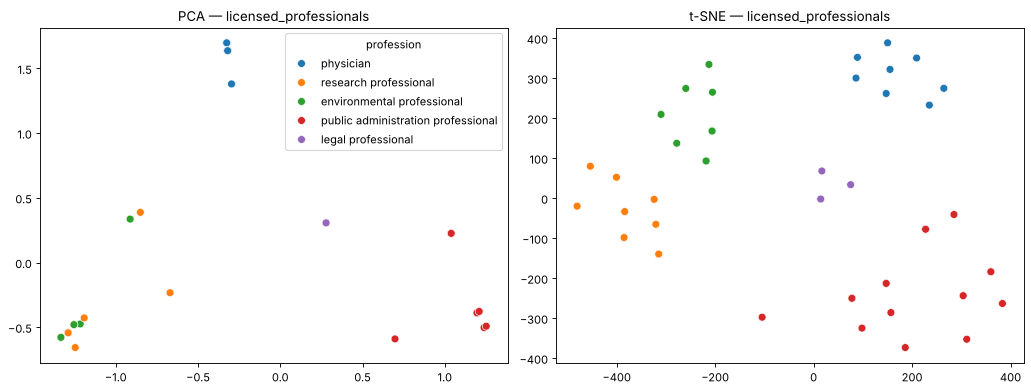

In [16]:
projections(X_lp.values, couleur=lp["profession"], titre="licensed_professionals")

Les variables étant toutes nominales, on part sur le **clustering agglomératif avec la distance de Hamming** (liaison average), et on le compare à un K-Means.

In [17]:
choix_k_cah_hamming(X_lp.values)

,2,3,4,5,6,7
silhouette (Hamming),0.457,0.586,0.673,0.691,0.686,0.669


Silhouette CAH (Hamming) : 0.67
ARI CAH vs K-Means       : 1.00
K-Means   0   1  2  3
CAH                  
0        19   0  0  0
1         0  21  0  0
2         0   0  8  0
3         0   0  0  5


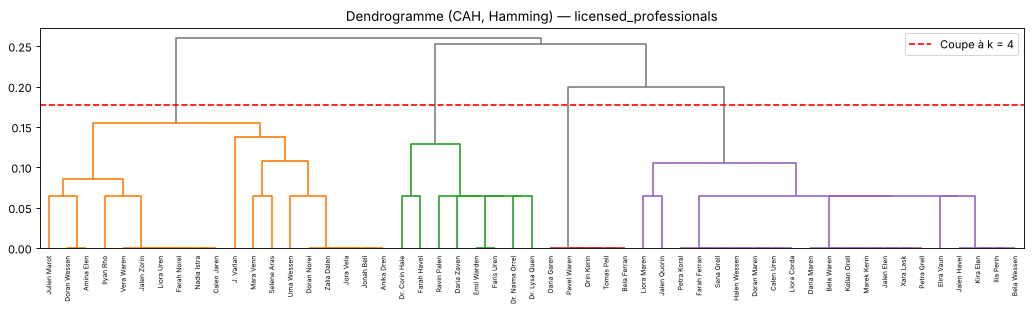

,n,profession,specialty,facility,registered_region,disciplinary_status
0,19,environmental professional (53%),environmental assessment (32%),FAC-AVL-301 (100%),Aveloran (84%),none (95%)
1,21,public administration professional (100%),programme administration (100%),aucun (100%),Kintaran (38%),none (90%)
2,8,physician (100%),cardiology (25%),FAC-VLN-101 (75%),Valennan (100%),none (100%)
3,5,legal professional (100%),regulatory compliance (100%),aucun (100%),Nordhaven (100%),none (100%)


In [18]:
k_lp = 4
Z = linkage(X_lp.values.astype(float), method="average", metric="hamming")
seuil = (Z[-k_lp, 2] + Z[-(k_lp - 1), 2]) / 2
plt.figure(figsize=(13, 4))
dendrogram(Z, labels=lp["professional_name"].values, leaf_font_size=6, color_threshold=seuil, above_threshold_color="grey")
plt.axhline(y=seuil, color="r", linestyle="--", label=f"Coupe à k = {k_lp}")
plt.title("Dendrogramme (CAH, Hamming) — licensed_professionals"); plt.legend(); plt.tight_layout(); plt.show()

lp["Cluster_Agglom"] = AgglomerativeClustering(n_clusters=k_lp, metric="hamming", linkage="average").fit_predict(X_lp.values)
lp["Cluster_KMeans"] = KMeans(n_clusters=k_lp, n_init=20, random_state=42).fit_predict(X_lp.values)
print(f"Silhouette CAH (Hamming) : {silhouette_score(X_lp.values, lp['Cluster_Agglom'], metric='hamming'):.2f}")
print(f"ARI CAH vs K-Means       : {adjusted_rand_score(lp['Cluster_Agglom'], lp['Cluster_KMeans']):.2f}")
print(pd.crosstab(lp["Cluster_Agglom"], lp["Cluster_KMeans"], rownames=["CAH"], colnames=["K-Means"]))
profil_clusters(lp, lp["Cluster_Agglom"].values, cols_lp)

{-1: 3, 0: 6, 1: 8, 2: 10, 3: 21, 4: 5}


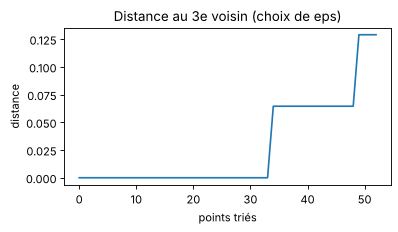

,professional_name,profession,specialty,facility,registered_region,disciplinary_status,license_issue_date
2,Dr. Corin Hale,physician,cardiac imaging,FAC-AVL-201,Valennan,none,2002-07-01
5,Farah Havel,physician,occupational medicine,FAC-AVL-201,Valennan,none,2026-07-01
6,J. Varlan,research professional,ecological analytics,FAC-AVL-301,Kintaran,none,1886-07-01


In [19]:
courbe_eps(X_lp.values, k=3, metric="hamming")
lp["Cluster_DBSCAN"] = DBSCAN(eps=0.1, min_samples=3, metric="hamming").fit_predict(X_lp.values)
print(lp["Cluster_DBSCAN"].value_counts().sort_index().to_dict())
lp.loc[lp["Cluster_DBSCAN"] == -1, ["professional_name"] + cols_lp + ["license_issue_date"]]

### c) Interprétation des clusters de licensed_professionals
La silhouette (Hamming) est bonne : 0,67 à k = 4, à peine plus à k = 5 (0,69). On retient **k = 4**, plus lisible. Le K-Means retrouve **exactement** les mêmes groupes (ARI = 1) : la structure est très nette.
- **Cluster 0 — « Le laboratoire Threshold Earth » (19)** : 100 % rattachés au laboratoire FAC-AVL-301, surtout Avelorans. Environnementalistes (10) et chercheurs (9), dont **2 en recherche clinique** (Mara Venn, Selene Aras) : atypique pour un laboratoire environnemental, cohérent avec son service de *non-invasive human assessment*.
- **Cluster 1 — « Les administrateurs publics » (21)** : 100 % *programme administration*, sans établissement, toutes régions. Ce sont les titulaires de `public_appointments`.
- **Cluster 2 — « Les médecins d'Asterion » (8)** : 100 % médecins valennans, à 75 % sur le campus FAC-VLN-101, les autres à la clinique aveloranne FAC-AVL-201.
- **Cluster 3 — « Les juristes » (5)** : 100 % juristes nordhaveniens en conformité réglementaire.

**DBSCAN** (Hamming, eps = 0,1) retrouve ces groupes et isole **3 profils sans semblable** : les 2 médecins de la clinique aveloranne d'Asterion (Corin Hale ; Farah Havel, licence datée de **2026**) et **J. Varlan**, dont la licence date de **1886** et est toujours active. On retrouve un nom de la « lignée » repérée dans `officer_filings`.

---
## 5. institutional_memos et 6. public_and_investigative_documents

### a) choix des variables
Comme pour `clinical_notes`, on ne regarde que les métadonnées : on exclut les identifiants, les dates, les auteurs, le titre et le texte (traité au bloc 6).

institutional_memos : (30, 12)
public_and_investigative_documents : (40, 11)
Types de documents (public_and_investigative) : 16 pour 40 lignes


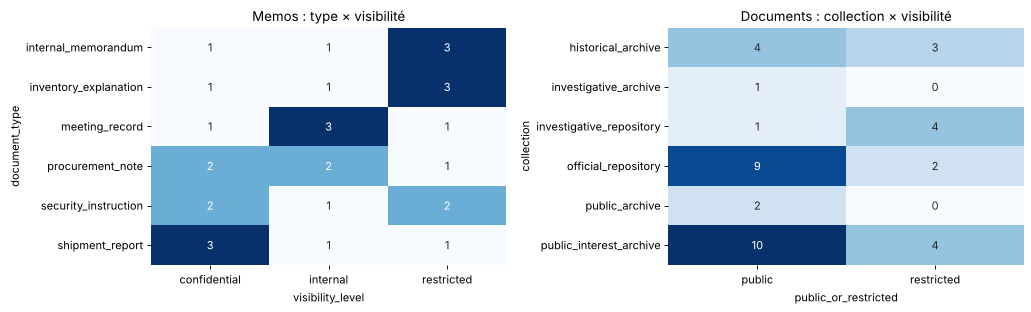

In [20]:
print("institutional_memos :", memos.shape)
ct_mem = pd.crosstab(memos["document_type"], memos["visibility_level"])
print("public_and_investigative_documents :", documents.shape)
ct_doc = pd.crosstab(documents["collection"], documents["public_or_restricted"])

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.heatmap(ct_mem, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0]); ax[0].set_title("Memos : type × visibilité")
sns.heatmap(ct_doc, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[1]); ax[1].set_title("Documents : collection × visibilité")
plt.tight_layout(); plt.show()
print("Types de documents (public_and_investigative) :", documents["document_type"].nunique(), "pour", len(documents), "lignes")

### Justification de l'absence de Clustering
Aucun algorithme de clustering n'est appliqué à `institutional_memos` ni à `public_and_investigative_documents`.
1. **Insuffisance de variables** : après exclusion des identifiants, dates, auteurs et textes, il ne reste que 2 variables nominales par fichier (type ou collection, et niveau de visibilité).
2. **Taille des datasets** : 30 et 40 documents. Les tableaux croisés suffisent à voir la répartition :
   - les memos sont parfaitement équilibrés (6 types × 5 documents), signe d'un gabarit de génération ; le niveau `restricted` n'est pas réservé à un type particulier ;
   - les documents publics ont 16 types pour 40 lignes, et la visibilité est répartie dans toutes les collections.
3. **Nature de l'information** : la valeur de ces fichiers est dans la colonne `text`, traitée au bloc 6.